# FloraSense C3 Experiment 2 — fixed-split A/B, hosted Colab T4

Upload both `c3_features_v2_20261022.zip` and `c3_experiment2_support.zip` to
**My Drive / FloraSense_C3 / experiment2**. Use Runtime → Change runtime type →
T4 GPU. Run cells in order. No local runtime, new splits or Experiment 1 weights.
Class 1 is Not Acceptable (root) / One Side (leaf: branch origins, not foliage).


In [1]:
# 1. Mount Drive
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
from google.colab import drive
drive.mount("/content/drive")
from pathlib import Path
DRIVE_DIR = Path("/content/drive/MyDrive/FloraSense_C3/experiment2")


Mounted at /content/drive


In [3]:
from pathlib import Path

base = Path("/content/drive/MyDrive/FloraSense_C3")

print("Folder exists:", base.exists())

for path in base.rglob("*.zip"):
    print(path)

Folder exists: True
/content/drive/MyDrive/FloraSense_C3/florasense_c3_training.zip
/content/drive/MyDrive/FloraSense_C3/florasense_c3_baseline_models.zip
/content/drive/MyDrive/FloraSense_C3/c3_features_v2_20261022.zip
/content/drive/MyDrive/FloraSense_C3/c3_experiment2_support.zip


In [4]:
# 2. Validate archives and extract into a fresh runtime directory
import hashlib, json, shutil, stat, zipfile
from datetime import datetime, timezone
def sha256(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream,"sha256").hexdigest()
DATA_SHA = "9c505bcbf13b130722da919502238c0a7d4c0e7449d88b73f8e70d3c22098ae4"
SUPPORT_SHA = "3eb95ca4b4266d4b980764e2d3d3203200fa35b1db4773bd8847e09404a3277b"
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
WORK = Path("/content") / ("c3_experiment2_" + stamp)
WORK.mkdir(exist_ok=False)
DATA_ROOT, CODE_ROOT = WORK / "dataset", WORK / "support"
for name, expected, destination in [
    ("c3_features_v2_20261022.zip",DATA_SHA,DATA_ROOT),
    ("c3_experiment2_support.zip",SUPPORT_SHA,CODE_ROOT)]:
    local = WORK / name
    shutil.copyfile(DRIVE_DIR / name,local)
    assert sha256(local)==expected, "Wrong or incomplete archive: " + name
    with zipfile.ZipFile(local) as archive:
        names=archive.namelist()
        assert len(names)==len(set(names))
        for member in archive.infolist():
            path=(destination/member.filename).resolve()
            assert path.is_relative_to(destination.resolve())
            assert ":" not in member.filename and "\\" not in member.filename
            assert not stat.S_ISLNK(member.external_attr >> 16)
        archive.extractall(destination)
print("Archives verified and extracted")


Archives verified and extracted


In [5]:
# 3. Dependencies and hosted GPU (keep Colab's matched CUDA torch/torchvision)
import sys, subprocess, platform
assert platform.system() != "Windows", "Hosted Colab only"
subprocess.check_call([sys.executable,"-m","pip","install","-q","scikit-learn==1.7.2","pandas>=2.2,<3","Pillow>=10","matplotlib>=3.8"])
import torch
assert torch.cuda.is_available(), "Select a T4 GPU runtime"
print("GPU",torch.cuda.get_device_name(0),"torch",torch.__version__)
sys.path.insert(0,str(CODE_ROOT))
from services.c3_quality_assessment.experiment2_training import validate_dataset, run_architecture, compare_results


GPU Tesla T4 torch 2.11.0+cu130


In [6]:
# 4. Validate all V2 data and six saved partitions; no model construction
release, manifests, splits = validate_dataset(DATA_ROOT)
print(release["dataset_version"],release["workbook_sha256"])
for task in ("root","leaf"):
    print(task,manifests[task].label.value_counts().to_dict())
    for fold,frame in enumerate(splits[task],1):
        print("fold",fold,frame.groupby(["split","label"]).size().to_dict())
RUN_ROOT = DRIVE_DIR / "runs" / stamp
print("Output:",RUN_ROOT)


c3_features_v2_20261022 90fe535179c5cc65b5458fba95dc95f2acbd46a4baa35f1935e1297805859486
root {'Acceptable': 90, 'Not Acceptable': 14}
fold 1 {('test', 'Acceptable'): 31, ('test', 'Not Acceptable'): 4, ('train', 'Acceptable'): 39, ('train', 'Not Acceptable'): 7, ('validation', 'Acceptable'): 20, ('validation', 'Not Acceptable'): 3}
fold 2 {('test', 'Acceptable'): 29, ('test', 'Not Acceptable'): 5, ('train', 'Acceptable'): 42, ('train', 'Not Acceptable'): 4, ('validation', 'Acceptable'): 19, ('validation', 'Not Acceptable'): 5}
fold 3 {('test', 'Acceptable'): 30, ('test', 'Not Acceptable'): 5, ('train', 'Acceptable'): 40, ('train', 'Not Acceptable'): 6, ('validation', 'Acceptable'): 20, ('validation', 'Not Acceptable'): 3}
leaf {'Both Sides': 74, 'One Side': 16}
fold 1 {('test', 'Both Sides'): 25, ('test', 'One Side'): 5, ('train', 'Both Sides'): 33, ('train', 'One Side'): 7, ('validation', 'Both Sides'): 16, ('validation', 'One Side'): 4}
fold 2 {('test', 'Both Sides'): 24, ('test', 'O

## Training configuration

Both approaches load the identical exported train/validation/test rows. Neither
outer nor inner folds are generated. Plant_ID namespaces Sample_ID; varieties
may appear across partitions as in Experiment 1. This is not held-out-variety
evaluation. Root and leaf remain independent. No Plant_ID feature is supplied.

Same original + two fixed augmentation tensors: EXIF orientation, fit to 208,
center on gray 224 canvas, ImageNet normalization, flip, ±4° rotation and mild
color jitter. No crops; junctions must remain visible. Training-only class
weights; seed 42 plus fold; AdamW, batch 16, head LR .001, layer4 LR .00001,
weight decay .01, up to 40 epochs, patience 6. B starts layer4 adaptation at
epoch 1 (no warm-up); both keep BatchNorm running statistics frozen. Validation
weighted loss selects checkpoints. Test partitions are evaluated only afterward.

A and B are initialized independently from ImageNet, never from a full-data
checkpoint. Review results jointly after both complete; do not tune B based on
A outer-test errors. Fold checkpoints are saved to Drive; no deployment refit or
test-selected best fold is produced. Rerunning an existing arm is refused.


In [7]:
# 5. Run architecture A: frozen backbone + head, separate root/leaf models
run_architecture(DATA_ROOT,RUN_ROOT,"A")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 181MB/s]


A/root fold 1: best epoch 18; {'confusion_matrix': [[27, 4], [3, 1]], 'matrix_order': ['Acceptable', 'Not Acceptable'], 'macro_f1': 0.5537340619307832, 'macro_f1_definition': 'fixed two-class macro; missing-class strata do not demonstrate two-class discrimination', 'balanced_accuracy': 0.560483870967742, 'minority_precision': 0.2, 'minority_recall': 0.25, 'classification_report': {'Acceptable': {'precision': 0.9, 'recall': 0.8709677419354839, 'f1-score': 0.8852459016393442, 'support': 31.0}, 'Not Acceptable': {'precision': 0.2, 'recall': 0.25, 'f1-score': 0.2222222222222222, 'support': 4.0}, 'accuracy': 0.8, 'macro avg': {'precision': 0.55, 'recall': 0.560483870967742, 'f1-score': 0.5537340619307832, 'support': 35.0}, 'weighted avg': {'precision': 0.8200000000000001, 'recall': 0.8, 'f1-score': 0.809471766848816, 'support': 35.0}}}
A/root fold 2: best epoch 6; {'confusion_matrix': [[25, 4], [4, 1]], 'matrix_order': ['Acceptable', 'Not Acceptable'], 'macro_f1': 0.5310344827586206, 'macro

'/content/drive/MyDrive/FloraSense_C3/experiment2/runs/20261021T191450487281Z/A'

In [8]:
# 6. Run architecture B: layer4 + head, exact same saved partitions/images
run_architecture(DATA_ROOT,RUN_ROOT,"B")


B/root fold 1: best epoch 6; {'confusion_matrix': [[29, 2], [3, 1]], 'matrix_order': ['Acceptable', 'Not Acceptable'], 'macro_f1': 0.6031746031746031, 'macro_f1_definition': 'fixed two-class macro; missing-class strata do not demonstrate two-class discrimination', 'balanced_accuracy': 0.592741935483871, 'minority_precision': 0.3333333333333333, 'minority_recall': 0.25, 'classification_report': {'Acceptable': {'precision': 0.90625, 'recall': 0.9354838709677419, 'f1-score': 0.9206349206349206, 'support': 31.0}, 'Not Acceptable': {'precision': 0.3333333333333333, 'recall': 0.25, 'f1-score': 0.2857142857142857, 'support': 4.0}, 'accuracy': 0.8571428571428571, 'macro avg': {'precision': 0.6197916666666666, 'recall': 0.592741935483871, 'f1-score': 0.6031746031746031, 'support': 35.0}, 'weighted avg': {'precision': 0.8407738095238095, 'recall': 0.8571428571428571, 'f1-score': 0.8480725623582765, 'support': 35.0}}}
B/root fold 2: best epoch 2; {'confusion_matrix': [[26, 3], [4, 1]], 'matrix_or

'/content/drive/MyDrive/FloraSense_C3/experiment2/runs/20261021T191450487281Z/B'

This trains ResNet18's layer4 and classification head for both root and leaf classification.

Combined confusion matrices

,task,Plant_ID,metric,A,B,B_minus_A
0,root,ALL,macro_f1,0.601968,0.648352,0.046383
1,root,ALL,balanced_accuracy,0.611905,0.639683,0.027778
2,root,ALL,minority_precision,0.294118,0.416667,0.122549
3,root,ALL,minority_recall,0.357143,0.357143,0.000000
4,root,P01,macro_f1,0.461538,0.461538,0.000000
5,root,P01,balanced_accuracy,0.461538,0.461538,0.000000
6,root,P01,minority_precision,0.000000,0.000000,0.000000
7,root,P01,minority_recall,0.000000,0.000000,0.000000
8,root,P02,macro_f1,0.666667,0.666667,0.000000
9,root,P02,balanced_accuracy,0.654545,0.654545,0.000000


# Experiment 2 A/B comparison

All results use V2 corrected targets and identical saved train/validation/test partitions.

| Task | Metric | A | B | B - A |
|---|---|---:|---:|---:|
| root | macro_f1 | 0.6019682886823401 | 0.6483516483516484 | 0.04638335966930829 |
| root | balanced_accuracy | 0.611904761904762 | 0.6396825396825397 | 0.02777777777777779 |
| root | minority_precision | 0.29411764705882354 | 0.4166666666666667 | 0.12254901960784315 |
| root | minority_recall | 0.35714285714285715 | 0.35714285714285715 | 0.0 |
| leaf | macro_f1 | 0.5132211538461539 | 0.5079278294149809 | -0.005293324431172919 |
| leaf | balanced_accuracy | 0.5608108108108107 | 0.6072635135135135 | 0.04645270270270274 |
| leaf | minority_precision | 0.2222222222222222 | 0.2391304347826087 | 0.016908212560386493 |
| leaf | minority_recall | 0.5 | 0.6875 | 0.1875 |

See model_comparison.csv for per-plant differences and paired CSVs for sample disagreements. All fold results remain in evaluation.json. Small m

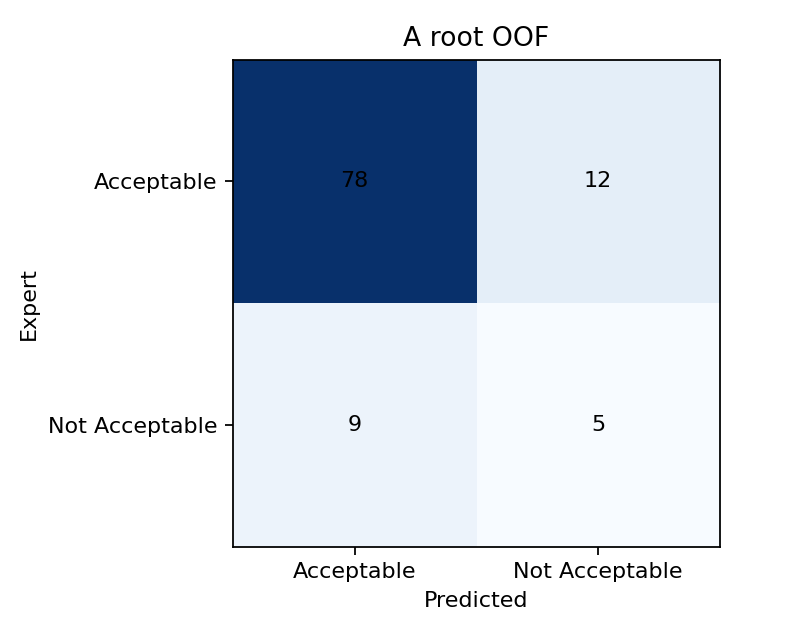

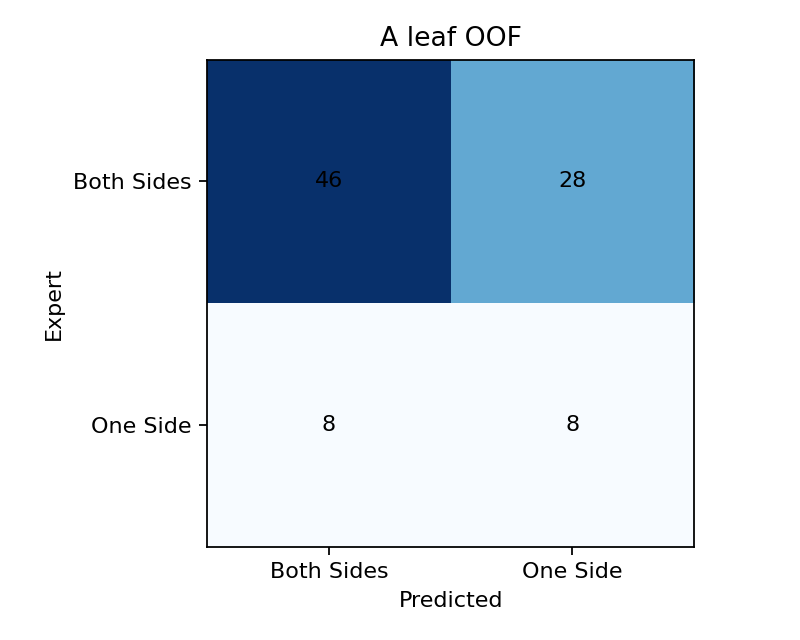

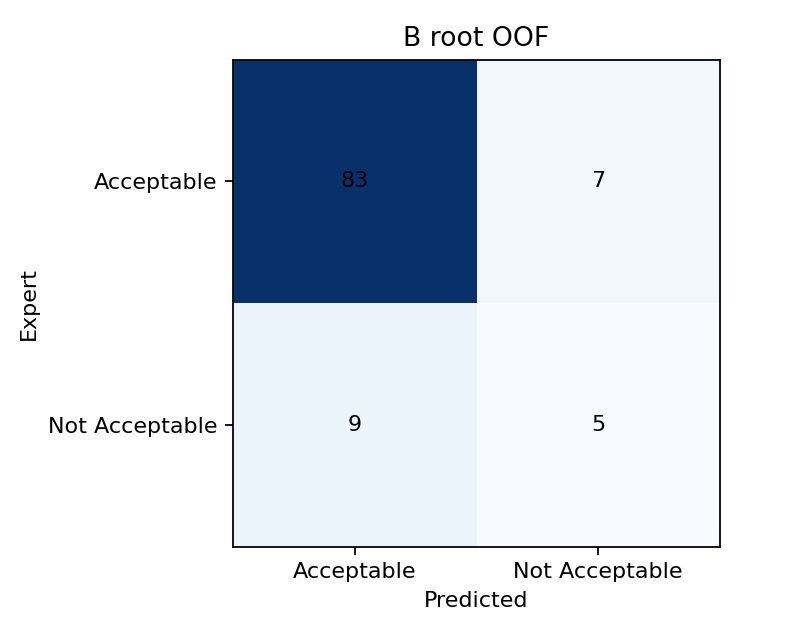

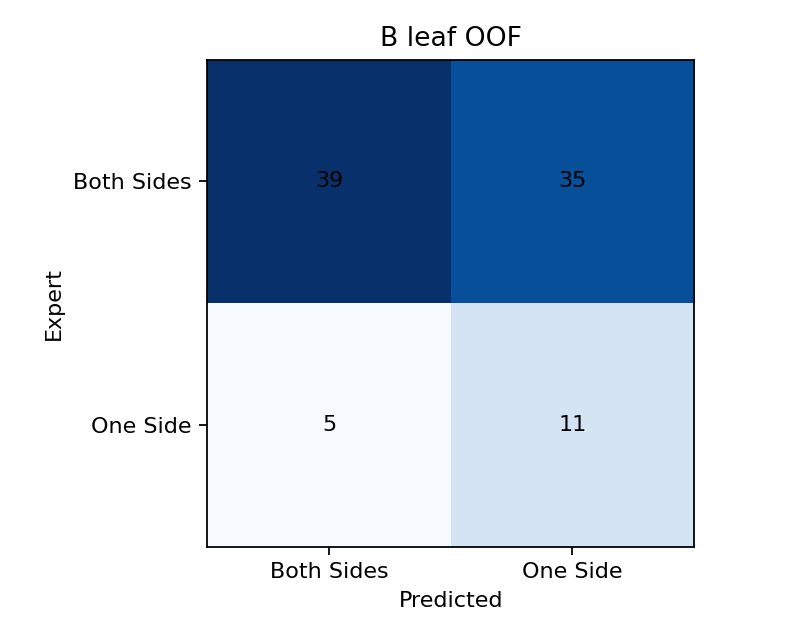

In [9]:
import pandas as pd

compare_results(RUN_ROOT)

display(pd.read_csv(RUN_ROOT / "model_comparison.csv"))
print((RUN_ROOT / "comparison_report.md").read_text())

from IPython.display import display, Image as DisplayImage

for architecture in ("A", "B"):
    for task in ("root", "leaf"):
        display(
            DisplayImage(
                filename=str(
                    RUN_ROOT / architecture / task / "confusion_matrix.png"
                )
            )
        )

**Root: Architecture B is the better candidate**

Fine-tuning improves macro-F1 by 0.046 and balanced accuracy by 2.8 percentage points. However, it still misses 9 of the 14 unacceptable roots.

> Add blockquote



**Leaf: No clear overall winner**

Architecture B detects more One Side cases but produces more false alarms. Its macro-F1 is slightly lower than A.

In [10]:
from google.colab import files

archive = shutil.make_archive(
    "/content/c3_experiment2_models",
    "zip",
    root_dir=RUN_ROOT
)

backup = RUN_ROOT.parent / (stamp + "_models.zip")
shutil.copyfile(archive, backup)

print("Drive backup:", backup)
files.download(archive)


Drive backup: /content/drive/MyDrive/FloraSense_C3/experiment2/runs/20261021T191450487281Z_models.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Limits and inference handoff

Checkpoints: `{A,B}/{root,leaf}/fold_{1,2,3}.pth`, each with full ResNet18 state,
class mapping, preprocessing and dataset/split provenance. These are fold models;
no full-data final_model.pth is selected by outer scores. Original Experiment 1
artifacts are not used or modified.

The state-dict structure matches C3 inference, but the current general-quality
loader uses a hardcoded path and a different resize transform. Do not replace
its checkpoint. Future feature inference must use the task-specific path/classes
and exact metadata preprocessing (EXIF + contain/padding + normalization).

Minority support is small; corrected P07 has no unacceptable roots, P05 no One
Side leaves and P08 no data. Missing-class per-plant metrics are unavailable.
Previously reviewed outer data is a comparative benchmark, not a fresh external
test. Branch qualification/visibility issues remain; no labels are altered or
test examples excluded. Colab disconnects preserve Drive checkpoints; resume is
not implemented, so start a new run directory after interruption.
